<a href="https://colab.research.google.com/github/sanketkandalkar46-del/dsa-pp/blob/main/AIML_Practical1_Data_Preparation_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# AIML Practical 1 – Data Preparation and Exploratory Data Analysis
**Course:** Artificial Intelligence & Machine Learning Lab (PCC-305-ITT) | **Class:** T.E. IT | **Group B – Assignment 1**

**Problem Statement:** Download a standard dataset (Titanic) and perform data cleaning, missing value handling, feature scaling, encoding, statistical analysis, visualization (histogram, boxplot) and train-test split.

## 0. Upload `titanic.csv` (Google Colab)
Run this cell and choose your Titanic CSV file. If your file has a different name (e.g. `Titanic-Dataset.csv`), rename it to `titanic.csv` or change the filename in step 1.

In [8]:
from google.colab import files
uploaded = files.upload()
print(list(uploaded.keys()))

Saving Titanic-Dataset.csv to Titanic-Dataset (1).csv
['Titanic-Dataset (1).csv']


## Imports

In [9]:
# Titanic Dataset Analysis
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split

## 1. Load dataset from CSV

In [10]:
titanic = pd.read_csv("Titanic-Dataset.csv")
titanic.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [11]:
print(titanic.shape)
titanic.info()

(891, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


## 2. Data Cleaning
Drop irrelevant columns (`Cabin` has too many missing values).

In [12]:
titanic = titanic.drop(['Cabin'], axis=1)
titanic.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,S


## 3. Missing Value Handling
Numeric → median, Categorical → mode.

In [13]:
print(titanic.isnull().sum())

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Embarked         2
dtype: int64


In [14]:
# Fill numeric missing values with median
titanic['Age'] = titanic['Age'].fillna(titanic['Age'].median())

# Fill categorical missing values with mode
titanic['Embarked'] = titanic['Embarked'].fillna(titanic['Embarked'].mode()[0])

print(titanic.isnull().sum())

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64


## 4. Feature Scaling (StandardScaler)

In [15]:
scaler = StandardScaler()
titanic['Fare_scaled'] = scaler.fit_transform(titanic[['Fare']])
titanic[['Fare', 'Fare_scaled']].head()

,Fare,Fare_scaled
0,7.2500,-0.502445
1,71.2833,0.786845
2,7.9250,-0.488854
3,53.1000,0.420730
4,8.0500,-0.486337


## 5. Encoding Techniques (Label Encoding)

In [16]:
encoder = LabelEncoder()
titanic['Sex_encoded'] = encoder.fit_transform(titanic['Sex'])
titanic['Class_encoded'] = encoder.fit_transform(titanic['Pclass'])
titanic[['Sex', 'Sex_encoded', 'Pclass', 'Class_encoded']].head()

,Sex,Sex_encoded,Pclass,Class_encoded
0,male,1,3,2
1,female,0,1,0
2,female,0,3,2
3,female,0,1,0
4,male,1,3,2


## 6. Statistical Analysis

In [17]:
titanic.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare,Fare_scaled,Sex_encoded,Class_encoded
count,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,8.910000e+02,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.361582,0.523008,0.381594,32.204208,3.987333e-18,0.647587,1.308642
std,257.353842,0.486592,0.836071,13.019697,1.102743,0.806057,49.693429,1.000562e+00,0.477990,0.836071
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000,-6.484217e-01,0.000000,0.000000
25%,223.500000,0.000000,2.000000,22.000000,0.000000,0.000000,7.910400,-4.891482e-01,0.000000,1.000000
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200,-3.573909e-01,1.000000,2.000000
75%,668.500000,1.000000,3.000000,35.000000,1.000000,0.000000,31.000000,-2.424635e-02,1.000000,2.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200,9.667167e+00,1.000000,2.000000


## 7. Data Visualization (Seaborn)

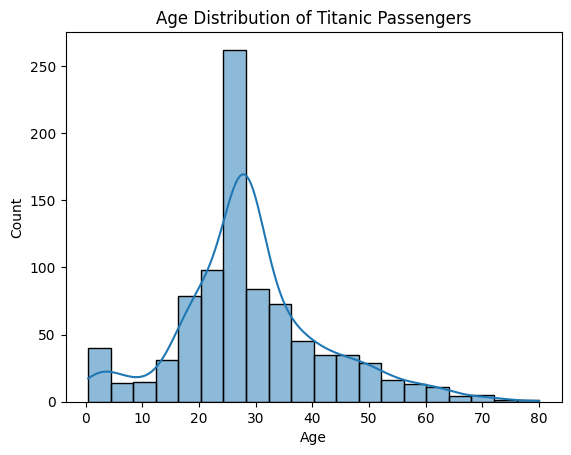

In [18]:
# Histogram of Age
sns.histplot(titanic["Age"], bins=20, kde=True)
plt.title("Age Distribution of Titanic Passengers")
plt.show()

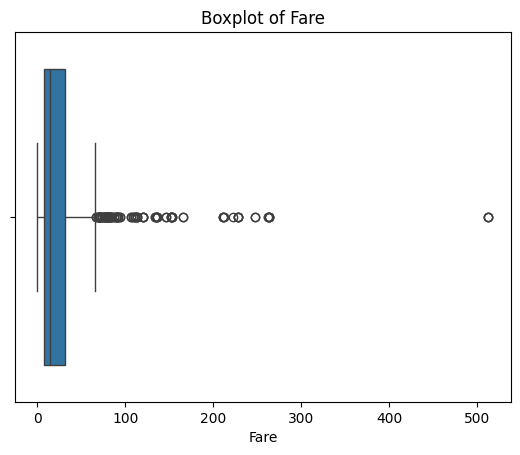

In [19]:
# Boxplot of Fare
sns.boxplot(x=titanic["Fare"])
plt.title("Boxplot of Fare")
plt.show()

## 8. Train-Test Split

In [20]:
X = titanic[['Age', 'Fare_scaled', 'Sex_encoded', 'Class_encoded']]
y = titanic['Survived']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

print("Training set shape:", X_train.shape)
print("Test set shape:", X_test.shape)

Training set shape: (712, 4)
Test set shape: (179, 4)


## Conclusion
Thus we have studied different data preparation techniques.